In [1]:
import os
import h5py
import numpy as np
import pandas as pd

DATA_DIR = "../dataset"
paths = {
    1: "MIT_LFP_DS/2017-05-12_batchdata_updated_struct_errorcorrect.mat",
    2: "MIT_LFP_DS/2017-06-30_batchdata_updated_struct_errorcorrect.mat",
    3: "MIT_LFP_DS/2018-04-12_batchdata_updated_struct_errorcorrect.mat",
}
os.makedirs("processed", exist_ok=True)

# The .mat files are MATLAB v7.3, which is HDF5 inside, so h5py can read them
files = {b: h5py.File(os.path.join(DATA_DIR, p), "r") for b, p in paths.items()}

for b, f in files.items():
    B = f["batch"]
    print(f"Batch {b}: {B['summary'].shape[0]} cells | fields: {list(B.keys())}")

Batch 1: 46 cells | fields: ['Vdlin', 'barcode', 'channel_id', 'cycle_life', 'cycles', 'policy', 'policy_readable', 'summary']
Batch 2: 48 cells | fields: ['Vdlin', 'barcode', 'channel_id', 'cycle_life', 'cycles', 'policy', 'policy_readable', 'summary']
Batch 3: 46 cells | fields: ['Vdlin', 'barcode', 'channel_id', 'cycle_life', 'cycles', 'policy', 'policy_readable', 'summary']


In [2]:
def read_string(f, ref):
    # MATLAB stores text as 2-byte characters; keep every second byte
    return np.array(f[ref]).tobytes()[::2].decode()

def read_scalar(f, ref):
    v = np.array(f[ref]).ravel()
    return float(v[0]) if v.size else np.nan

rows = []
for b, f in files.items():
    B = f["batch"]
    for i in range(B["summary"].shape[0]):
        rows.append({
            "batch": b, "cell": i, "cell_id": f"b{b}c{i}",
            "cycle_life": read_scalar(f, B["cycle_life"][i, 0]),
            "policy": read_string(f, B["policy_readable"][i, 0]),
        })
cells = pd.DataFrame(rows)

# Batch-1 cells 0-4 kept cycling in batch 2 (as b2c7, b2c8, b2c9, b2c15, b2c16).
# Add the extra cycles they ran there to their cycle life.
continued = {0: 7, 1: 8, 2: 9, 3: 15, 4: 16}
extra_cycles = {0: 662, 1: 981, 2: 1060, 3: 208, 4: 482}
for c1, add in extra_cycles.items():
    cells.loc[cells.cell_id == f"b1c{c1}", "cycle_life"] += add

# Remove faulty cells and the batch-2 duplicates (the authors' cleaning rules)
remove = ["b1c8", "b1c10", "b1c12", "b1c13", "b1c22",
          "b2c7", "b2c8", "b2c9", "b2c15", "b2c16",
          "b3c2", "b3c23", "b3c32", "b3c37", "b3c42", "b3c43"]
cells = cells[~cells.cell_id.isin(remove)].reset_index(drop=True)
cells["cycle_life"] = cells["cycle_life"].astype(int)

print(cells.groupby("batch").size().rename("cells"))
print("Total cells:", len(cells))
print("\nCycle life:\n", cells.cycle_life.describe().round(1))
print("\nCheck b1c0:", cells.loc[cells.cell_id == "b1c0", "cycle_life"].item(), "(expected 1852)")
cells.to_csv("processed/cells_meta.csv", index=False)

batch
1    41
2    43
3    40
Name: cells, dtype: int64
Total cells: 124

Cycle life:
 count     124.0
mean      801.6
std       379.7
min       148.0
25%       498.8
50%       736.5
75%       946.5
max      2237.0
Name: cycle_life, dtype: float64

Check b1c0: 1852 (expected 1852)


In [3]:
SUMMARY_KEYS = ["cycle", "QDischarge", "QCharge", "IR", "Tavg", "Tmin", "Tmax", "chargetime"]
NOMINAL_AH = 1.1           # rated capacity of these LFP cells

def load_summary(f, i):
    """One row per cycle for cell i: capacity, resistance, temperatures, charge time."""
    S = f[f["batch"]["summary"][i, 0]]
    return pd.DataFrame({k: np.array(S[k]).ravel() for k in SUMMARY_KEYS})

def full_summary(r):
    """Summary for one cell; batch-1 cells 0-4 get their batch-2 cycles joined on."""
    s = load_summary(files[r.batch], r.cell)
    if r.batch == 1 and r.cell in continued:
        s2 = load_summary(files[2], continued[r.cell])
        s2["cycle"] = s2["cycle"] + s["cycle"].max()
        s = pd.concat([s, s2], ignore_index=True)
    return s

rows, removed = [], 0
for _, r in cells.iterrows():
    s = full_summary(r)
    n0 = len(s)

    # 1) Drop impossible capacity readings
    s = s[(s.QDischarge > 0.5) & (s.QDischarge < 1.2)].copy()
    # 2) Drop one-cycle spikes: points far from the local trend
    trend = s.QDischarge.rolling(9, center=True, min_periods=1).median()
    s = s[(s.QDischarge - trend).abs() < 0.03]
    removed += n0 - len(s)

    # 3) Bad sensor values become missing (keep the cycle, lose only that value)
    s.loc[s.IR <= 0, "IR"] = np.nan
    s.loc[s.chargetime > 3 * s.chargetime.median(), "chargetime"] = np.nan

    s["cell_id"], s["batch"], s["policy"] = r.cell_id, r.batch, r.policy
    s["cycle_life"] = r.cycle_life
    rows.append(s)

data = pd.concat(rows, ignore_index=True)
data["SOH"] = data.QDischarge / NOMINAL_AH * 100        # state of health, %
data["RUL"] = data.cycle_life - data.cycle              # remaining useful life, cycles
data["before_eol"] = data.RUL >= 0                      # still above end of life

print("Rows (cell-cycles):", len(data), "| Cells:", data.cell_id.nunique(),
      "| Rows removed as bad:", removed)
print("\nMissing values:\n", data[["IR", "chargetime", "Tavg"]].isna().sum())
print("\n", data.drop(columns=["batch"]).describe().T.round(3))
print("\nb1c0 last cycle:", int(data[data.cell_id == "b1c0"].cycle.max()), "(expected about 1852 or more)")
data.to_csv("processed/all_cells_summary.csv", index=False)
print("Saved processed/all_cells_summary.csv")

Rows (cell-cycles): 100440 | Cells: 124 | Rows removed as bad: 61

Missing values:
 IR            19
chargetime    26
Tavg           0
dtype: int64

                count     mean      std      min      25%      50%       75%  \
cycle       100440.0  490.371  387.999    1.000  204.000  409.000   675.000   
QDischarge  100440.0    1.031    0.052    0.825    1.014    1.049     1.068   
QCharge     100440.0    1.031    0.052    0.805    1.014    1.049     1.067   
IR          100421.0    0.017    0.001    0.013    0.016    0.017     0.017   
Tavg        100440.0   34.084    1.891   25.038   32.837   33.901    35.348   
Tmin        100440.0   31.225    1.507   20.615   30.075   30.952    32.352   
Tmax        100440.0   37.808    2.536   25.938   36.186   38.025    39.706   
chargetime  100414.0   11.106    1.763    8.897   10.050   10.335    11.430   
cycle_life  100440.0  974.190  466.654  148.000  636.000  862.000  1093.000   
SOH         100440.0   93.753    4.710   75.004   92.189   9

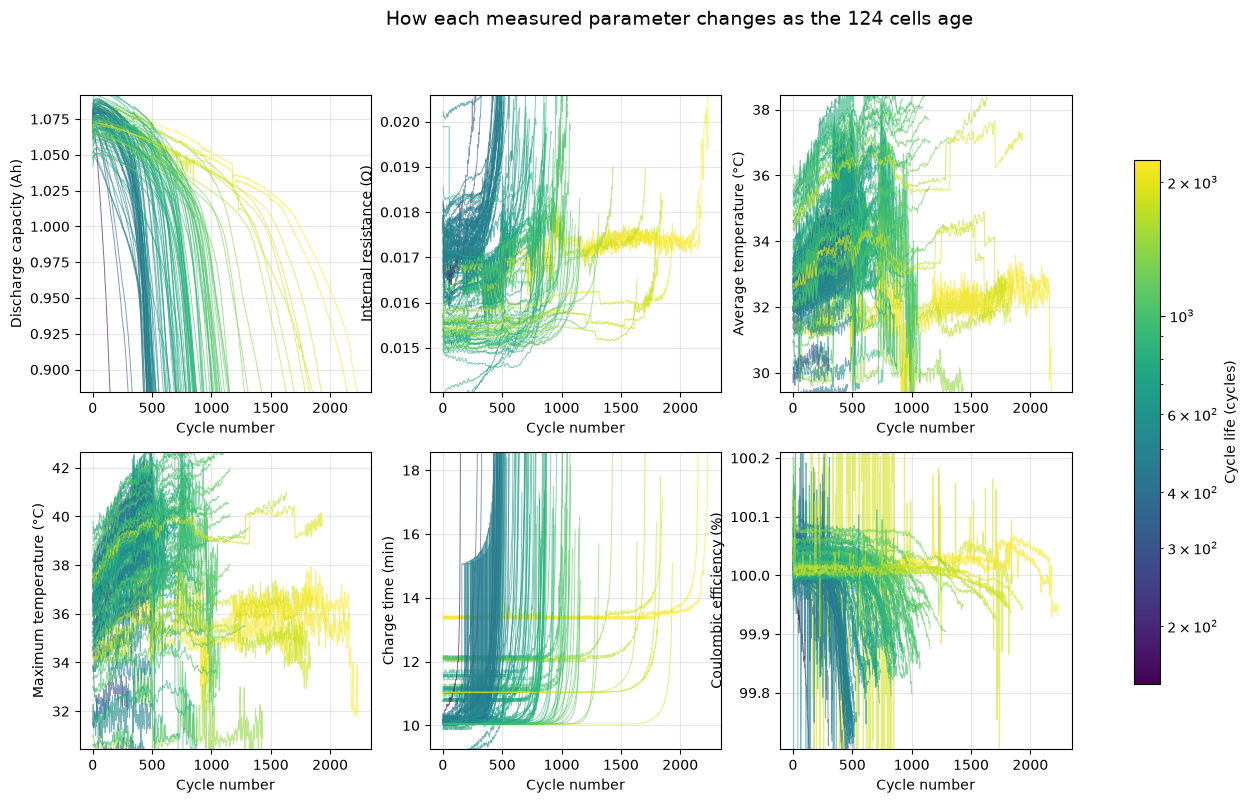

Typical values (median across all cycles):
QDischarge      1.0496
IR              0.0166
Tavg           33.9002
Tmax           38.0083
chargetime     10.3118
CE            100.0117
dtype: float64


In [4]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.cm import ScalarMappable

# Coulombic efficiency: share of the charge put in that came back out
data["CE"] = data.QDischarge / data.QCharge * 100

d = data[data.before_eol]          # life up to end of life (SOH 80%)

params = [
    ("QDischarge", "Discharge capacity (Ah)"),
    ("IR",         "Internal resistance (Ω)"),
    ("Tavg",       "Average temperature (°C)"),
    ("Tmax",       "Maximum temperature (°C)"),
    ("chargetime", "Charge time (min)"),
    ("CE",         "Coulombic efficiency (%)"),
]

norm = LogNorm(cells.cycle_life.min(), cells.cycle_life.max())
cmap = plt.cm.viridis              # purple = short life, yellow = long life

fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
for ax, (col, label) in zip(axes.flat, params):
    for _, g in d.groupby("cell_id"):
        y = g[col].rolling(5, center=True, min_periods=1).median()   # smooth sensor noise
        ax.plot(g.cycle, y, color=cmap(norm(g.cycle_life.iloc[0])), lw=0.7, alpha=0.6)
    ax.set_ylim(d[col].quantile(0.005), d[col].quantile(0.995))     # ignore extreme outliers
    ax.set(xlabel="Cycle number", ylabel=label)
    ax.grid(alpha=0.3)

fig.colorbar(ScalarMappable(norm, cmap), ax=axes, label="Cycle life (cycles)", shrink=0.8)
fig.suptitle("How each measured parameter changes as the 124 cells age", fontsize=14)
plt.show()

print("Typical values (median across all cycles):")
print(d[[c for c, _ in params]].median().round(4))

In [5]:
def around(g, col, c, w=5):
    """Median of a parameter in a small window around cycle c (robust to noise)."""
    return g.loc[g.cycle.between(c - w, c + w), col].median()

feats = []
for cid, g in data.groupby("cell_id"):
    row = {"cell_id": cid, "batch": g.batch.iloc[0], "cycle_life": g.cycle_life.iloc[0]}
    for col in ["QDischarge", "IR", "Tavg", "Tmax", "chargetime", "CE"]:
        row[f"{col}_at100"]     = around(g, col, 100)                       # level at cycle 100
        row[f"{col}_chg10_100"] = around(g, col, 100) - around(g, col, 10)  # change, cycle 10 to 100
    feats.append(row)

F = pd.DataFrame(feats)
F["log_life"] = np.log10(F.cycle_life)
cols = [c for c in F.columns if c.endswith(("_at100", "_chg10_100"))]

# Spearman correlation: does a higher value go with longer or shorter life? (-1 to +1)
corr = pd.DataFrame({"all cells": F[cols].corrwith(F.log_life, method="spearman")})
for b in [1, 2, 3]:
    sub = F[F.batch == b]
    corr[f"batch {b}"] = sub[cols].corrwith(sub.log_life, method="spearman")

print(corr.round(2).sort_values("all cells", key=abs, ascending=False))
F.to_csv("processed/early_features.csv", index=False)

                      all cells  batch 1  batch 2  batch 3
Tmax_chg10_100            -0.60    -0.49    -0.20    -0.13
IR_at100                  -0.59     0.26     0.04     0.23
chargetime_chg10_100      -0.40    -0.17    -0.33    -0.19
Tavg_chg10_100            -0.35    -0.51    -0.26    -0.05
CE_chg10_100               0.32    -0.23     0.12     0.28
Tmax_at100                -0.19    -0.38     0.00    -0.07
Tavg_at100                 0.16    -0.40     0.02     0.01
IR_chg10_100               0.14    -0.28    -0.09    -0.22
CE_at100                   0.13    -0.05     0.05     0.04
QDischarge_chg10_100       0.13     0.56     0.15     0.08
chargetime_at100          -0.05     0.61    -0.15     0.04
QDischarge_at100           0.02     0.33     0.28     0.27


In [6]:
print(pd.read_csv("processed/cells_meta.csv").head())
print(pd.read_csv("processed/early_features.csv").head())

   batch  cell cell_id  cycle_life          policy
0      1     0    b1c0        1852  3.6C(80%)-3.6C
1      1     1    b1c1        2160  3.6C(80%)-3.6C
2      1     2    b1c2        2237  3.6C(80%)-3.6C
3      1     3    b1c3        1434      4C(80%)-4C
4      1     4    b1c4        1709      4C(80%)-4C
  cell_id  batch  cycle_life  QDischarge_at100  QDischarge_chg10_100  \
0    b1c0      1        1852          1.075841              0.001659   
1    b1c1      1        2160          1.080674              0.000898   
2   b1c11      1         788          1.059947              0.002003   
3   b1c14      1         880          1.076202              0.001805   
4   b1c15      1         719          1.067738              0.002039   

   IR_at100  IR_chg10_100  Tavg_at100  Tavg_chg10_100  Tmax_at100  \
0  0.016678      0.000075   31.559122       -0.296446   35.386295   
1  0.016991      0.000128   31.210829       -0.455127   34.151352   
2  0.016278      0.000018   32.707720       -0.288509 